In [1]:
!pip install -q pymc-marketing==1.3.0 nutpie

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.


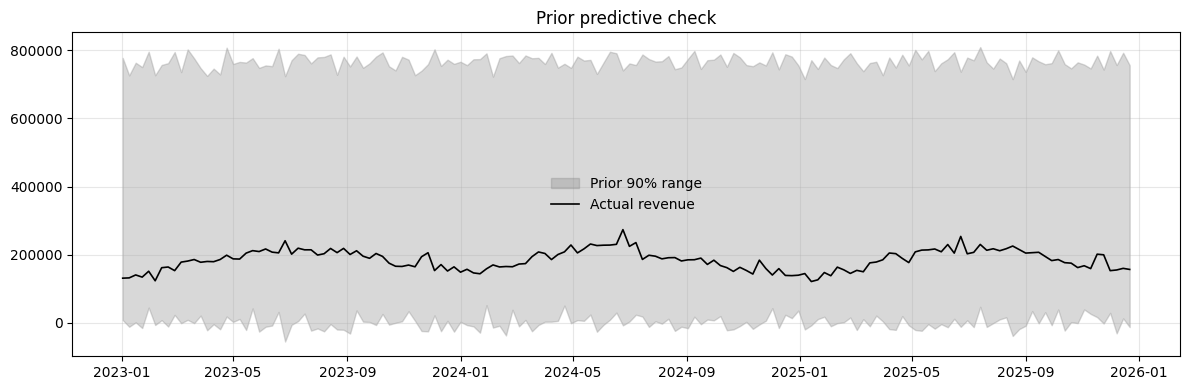

Output()

Output()

                                   mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
intercept_contribution             0.45    0.056     0.35     0.53     1162     1343  1.00    0.0017   0.0021
saturation_beta[google_search]     0.33     0.22      0.1     0.73      742     1010  1.01     0.008    0.012
saturation_beta[meta]             0.105      0.1    0.023     0.26     1302     1447  1.00    0.0029   0.0077
saturation_beta[microsoft]        0.079    0.053   0.0091     0.17     1296     1142  1.00    0.0014   0.0009
saturation_beta[youtube]          0.044    0.048   0.0039     0.13     2352     1853  1.00   0.00091   0.0017
saturation_lam[google_search]      1.78     1.04     0.51      3.6      999     1046  1.01     0.031    0.037
saturation_lam[meta]                2.6     1.77      0.5      5.9     1315     1293  1.00     0.044    0.034
saturation_lam[microsoft]          2.81      1.7     0.79        6     2119     2289  1.00     0.037    0.036
saturation

Output()


In-sample R²: 0.922 | MAPE: 3.6%


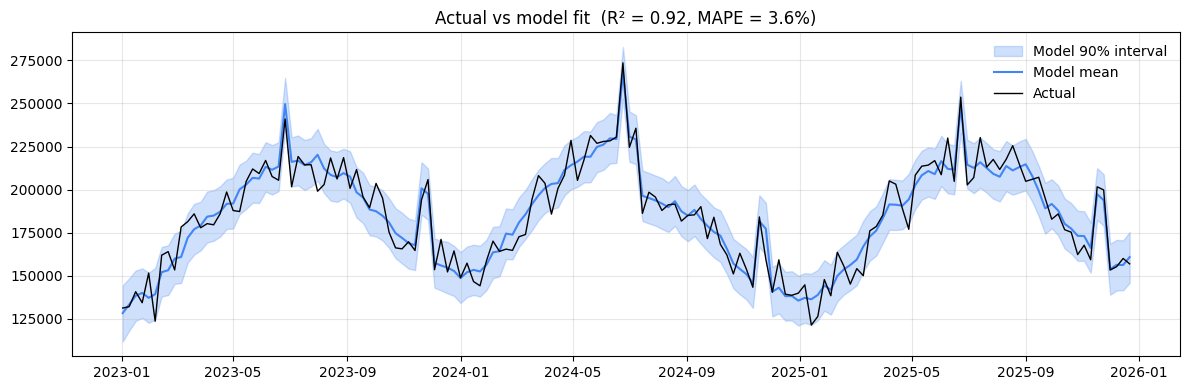

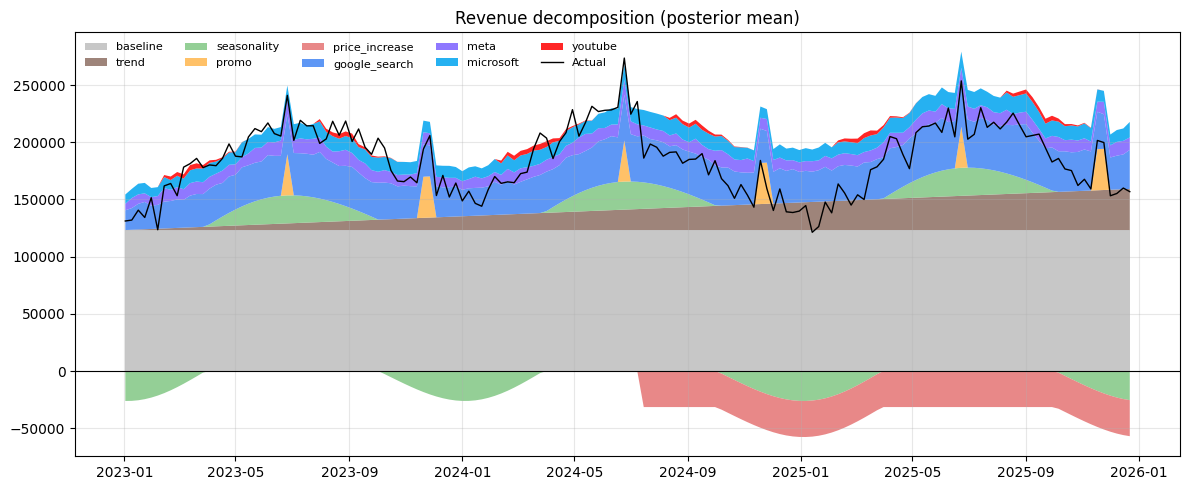


Media-driven share of revenue (model): 30.7%

Total contribution by component (USD):
baseline          19227958.0
google_search      5182697.0
trend              2802647.0
microsoft          1858125.0
meta               1640331.0
promo               323818.0
youtube             190027.0
seasonality          13883.0
price_increase    -2394754.0


In [1]:
# ============================================================
# Project 3 - Marketing Mix Model
# Step 3: Fit a Bayesian MMM with PyMC-Marketing
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
from pymc_extras.prior import Prior
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
SEED = 42

URL = "https://raw.githubusercontent.com/paolofelix/marketing-mix-model/main/data/mmm_data.csv"
df = pd.read_csv(URL, parse_dates=["date"])

channels = ["google_search", "meta", "microsoft", "youtube"]

# Controls (kept on a 0-1 scale so the sampler behaves)
df["trend"] = np.arange(len(df)) / (len(df) - 1)            # organic growth
df["price_increase"] = (df["price_index"] > 1).astype(int)  # 0 before, 1 after the +10% price change
controls = ["promo", "price_increase", "trend"]

X = df[["date"] + channels + controls]
y = df["revenue"]

# ------------------------------------------------------------
# 1. Priors - where domain knowledge goes in
# ------------------------------------------------------------
# a) Channel effect size scaled by share of spend: a channel we spend more on
#    is expected (a priori) to drive more revenue. Helps separate Google vs Microsoft.
spend_share = df[channels].sum() / df[channels].sum().sum()
beta_sigma = (spend_share / spend_share.mean() * 0.5).to_numpy()

# b) Carryover (adstock) by channel type:
#    search = short (people search when ready to buy), social = medium, video = long.
#                     google  meta  microsoft  youtube
adstock_a = np.array([1,      2,    1,         3])
adstock_b = np.array([3,      3,    3,         2])

model_config = {
    "intercept": Prior("Normal", mu=0.5, sigma=0.3),
    "saturation_beta": Prior("HalfNormal", sigma=beta_sigma, dims="channel"),
    "saturation_lam": Prior("Gamma", alpha=3, beta=1, dims="channel"),
    "adstock_alpha": Prior("Beta", alpha=adstock_a, beta=adstock_b, dims="channel"),
    "gamma_control": Prior("Normal", mu=0, sigma=0.5, dims="control"),
    "gamma_fourier": Prior("Laplace", mu=0, b=0.2, dims="fourier_mode"),
    "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
}

mmm = MMM(
    date_column="date",
    channel_columns=channels,
    control_columns=controls,
    target_column="revenue",
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
    model_config=model_config,
)

# ------------------------------------------------------------
# 2. Prior predictive check: do the priors produce plausible revenue
#    BEFORE the model sees the data?
# ------------------------------------------------------------
mmm.build_model(X, y)
prior = mmm.sample_prior_predictive(X, y, samples=500, random_seed=SEED)
y_scale = float(mmm.get_scales_as_xarray()["target_scale"])
prior_y = prior["y"].values.reshape(-1, len(df)) * y_scale

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(df["date"], *np.percentile(prior_y, [5, 95], axis=0), color="grey", alpha=0.3, label="Prior 90% range")
ax.plot(df["date"], y, color="black", lw=1.2, label="Actual revenue")
ax.set_title("Prior predictive check")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/05_prior_predictive.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 3. Fit with MCMC (nutpie sampler: ~1-3 min on Colab)
# ------------------------------------------------------------
mmm.fit(
    X, y,
    chains=4, draws=1000, tune=1500,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED,
)

# ------------------------------------------------------------
# 4. Convergence diagnostics
#    Good: 0 divergences, r_hat <= 1.01, ESS > 400
# ------------------------------------------------------------
params = ["intercept_contribution", "saturation_beta", "saturation_lam",
          "adstock_alpha", "gamma_control", "y_sigma"]
summary = az.summary(mmm.idata, var_names=params)
print(summary)
divergences = int(mmm.idata.sample_stats["diverging"].sum())
print(f"\nDivergences: {divergences} | max r_hat: {summary['r_hat'].astype(float).max():.3f} "
      f"| min ESS: {summary['ess_bulk'].astype(float).min():.0f}")

# ------------------------------------------------------------
# 5. In-sample fit: actual vs predicted
# ------------------------------------------------------------
post = mmm.sample_posterior_predictive(X, extend_idata=True, combined=True, random_seed=SEED)
pred = post["y"].transpose("date", "sample").values * y_scale   # shape: (weeks, samples)
pred_mean = pred.mean(axis=1)
lo, hi = np.percentile(pred, [5, 95], axis=1)

r2 = 1 - ((y - pred_mean) ** 2).sum() / ((y - y.mean()) ** 2).sum()
mape = (np.abs(y - pred_mean) / y).mean()
print(f"\nIn-sample R²: {r2:.3f} | MAPE: {mape:.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(df["date"], lo, hi, color="#4285F4", alpha=0.25, label="Model 90% interval")
ax.plot(df["date"], pred_mean, color="#4285F4", lw=1.5, label="Model mean")
ax.plot(df["date"], y, color="black", lw=1, label="Actual")
ax.set_title(f"Actual vs model fit  (R² = {r2:.2f}, MAPE = {mape:.1%})")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/06_model_fit.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 6. Revenue decomposition: what drove revenue each week?
# ------------------------------------------------------------
post_mean = mmm.idata.posterior.mean(("chain", "draw"))
decomp = pd.DataFrame(index=df["date"])
decomp["baseline"] = float(post_mean["intercept_contribution"]) * y_scale
decomp["seasonality"] = post_mean["yearly_seasonality_contribution"].values * y_scale
for c in controls:
    decomp[c] = post_mean["control_contribution"].sel(control=c).values * y_scale
for ch in channels:
    decomp[ch] = post_mean["channel_contribution"].sel(channel=ch).values * y_scale

order = ["baseline", "trend", "seasonality", "promo", "price_increase"] + channels
palette = ["#BDBDBD", "#8D6E63", "#81C784", "#FFB74D", "#E57373",
           "#4285F4", "#7B61FF", "#00A4EF", "#FF0000"]
pos = decomp[order].clip(lower=0)
neg = decomp[order].clip(upper=0)
fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(df["date"], pos.T.values, labels=order, colors=palette, alpha=0.85)
ax.stackplot(df["date"], neg.T.values, colors=palette, alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.plot(df["date"], y, color="black", lw=1, label="Actual")
ax.set_title("Revenue decomposition (posterior mean)")
ax.legend(loc="upper left", ncol=5, fontsize=8, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/07_decomposition.png", dpi=150)
plt.show()

media_share = decomp[channels].sum().sum() / y.sum()
print(f"\nMedia-driven share of revenue (model): {media_share:.1%}")
print("\nTotal contribution by component (USD):")
print(decomp.sum().round(0).sort_values(ascending=False).to_string())

               true_roas  mmm_mean  mmm_5%  mmm_95%  truth_in_90%_interval  naive_regression
channel                                                                                     
google_search       2.45      2.25    0.77     3.95                   True              6.64
meta                1.52      1.25    0.27     2.83                   True              1.69
microsoft           3.99      6.68    0.67    16.65                   True             -6.06
youtube             0.61      0.31    0.04     0.69                   True              0.02


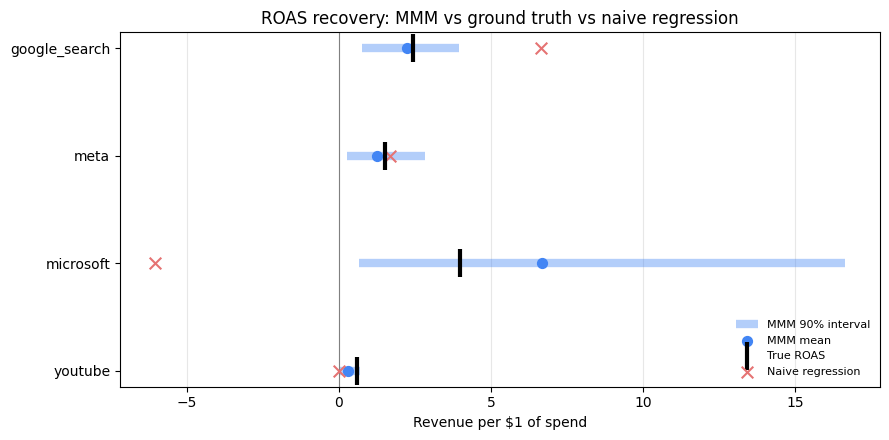


Carryover (adstock alpha) recovery
                true_alpha  mmm_mean  mmm_5%  mmm_95%
google_search        0.20      0.25    0.03     0.51
meta                 0.45      0.43    0.14     0.74
microsoft            0.20      0.25    0.02     0.57
youtube              0.70      0.61    0.26     0.90


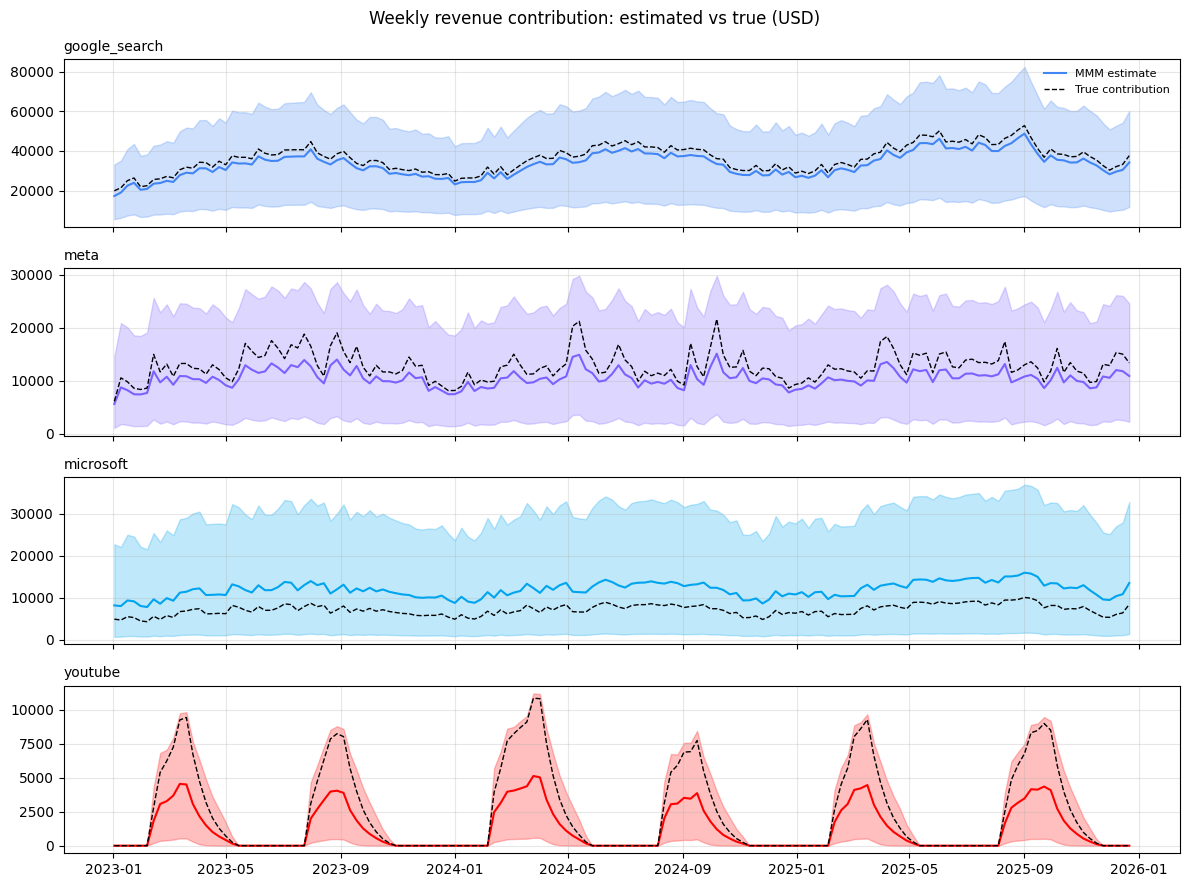

Output()

Output()

Output()


Holdout (last 13 weeks)  MAPE: 3.8% | actuals inside 90% interval: 100%


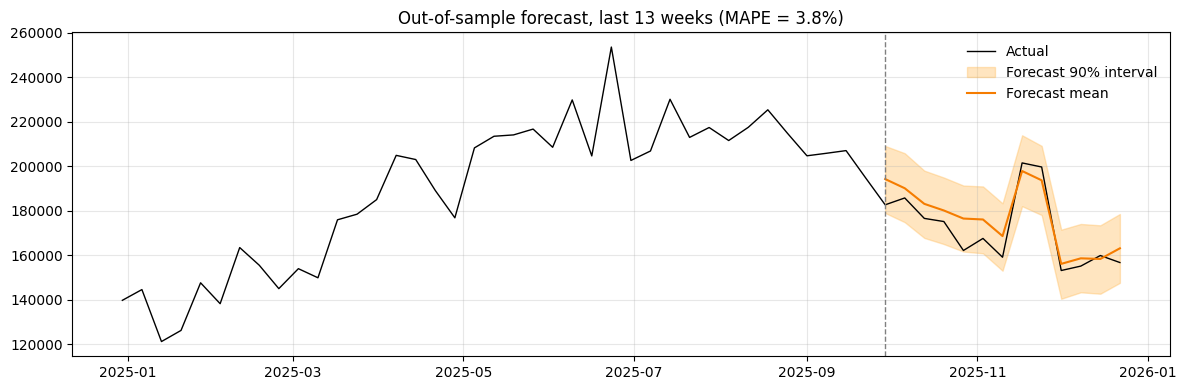

In [2]:
# ============================================================
# Project 3 - Marketing Mix Model
# Step 4: Validation - (a) ground-truth recovery, (b) 13-week holdout
# Run in the SAME notebook after Step 3 (uses mmm, df, X, y, y_scale, model_config)
# ============================================================
import json, urllib.request
pd.set_option("display.width", 200)

BASE = "https://raw.githubusercontent.com/paolofelix/marketing-mix-model/main/data/ground_truth/"
truth = json.loads(urllib.request.urlopen(BASE + "true_params.json").read())
gt = pd.read_csv(BASE + "ground_truth.csv", parse_dates=["date"])

colors = {"google_search": "#4285F4", "meta": "#7B61FF", "microsoft": "#00A4EF", "youtube": "#FF0000"}

# ------------------------------------------------------------
# A. ROAS recovery: model posterior vs true ROAS vs naive regression
# ------------------------------------------------------------
contrib_draws = mmm.idata.posterior["channel_contribution"].sum("date") * y_scale   # (chain, draw, channel)
spend_tot = df[channels].sum()

# naive regression from Step 2, for contrast
Xn = np.column_stack([np.ones(len(df)), df[channels]])
naive = np.linalg.lstsq(Xn, y, rcond=None)[0][1:]

rows = []
for i, ch in enumerate(channels):
    r = (contrib_draws.sel(channel=ch) / spend_tot[ch]).values.ravel()
    lo, hi = np.percentile(r, [5, 95])
    rows.append({
        "channel": ch,
        "true_roas": truth[ch]["true_roas"],
        "mmm_mean": r.mean(),
        "mmm_5%": lo,
        "mmm_95%": hi,
        "truth_in_90%_interval": lo <= truth[ch]["true_roas"] <= hi,
        "naive_regression": naive[i],
    })
roas = pd.DataFrame(rows).set_index("channel")
print(roas.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ypos = np.arange(len(channels))
ax.hlines(ypos, roas["mmm_5%"], roas["mmm_95%"], color="#4285F4", lw=6, alpha=0.4, label="MMM 90% interval")
ax.scatter(roas["mmm_mean"], ypos, color="#4285F4", s=50, zorder=3, label="MMM mean")
ax.scatter(roas["true_roas"], ypos, color="black", marker="|", s=400, lw=3, zorder=4, label="True ROAS")
ax.scatter(roas["naive_regression"], ypos, color="#E57373", marker="x", s=70, zorder=3, label="Naive regression")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(ypos, channels)
ax.invert_yaxis()
ax.set_xlabel("Revenue per $1 of spend")
ax.set_title("ROAS recovery: MMM vs ground truth vs naive regression")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig("figures/08_roas_recovery.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# B. Parameter recovery: carryover (adstock alpha)
# ------------------------------------------------------------
alpha_post = mmm.idata.posterior["adstock_alpha"]
alpha_tbl = pd.DataFrame({
    "true_alpha": [truth[ch]["alpha"] for ch in channels],
    "mmm_mean": [float(alpha_post.sel(channel=ch).mean()) for ch in channels],
    "mmm_5%": [float(alpha_post.sel(channel=ch).quantile(0.05)) for ch in channels],
    "mmm_95%": [float(alpha_post.sel(channel=ch).quantile(0.95)) for ch in channels],
}, index=channels)
print("\nCarryover (adstock alpha) recovery\n", alpha_tbl.round(2))

# ------------------------------------------------------------
# C. Weekly contribution recovery per channel
# ------------------------------------------------------------
cc = mmm.idata.posterior["channel_contribution"] * y_scale
fig, axes = plt.subplots(len(channels), 1, figsize=(12, 9), sharex=True)
for ax, ch in zip(axes, channels):
    draws = cc.sel(channel=ch).stack(s=("chain", "draw")).transpose("date", "s").values
    ax.fill_between(df["date"], *np.percentile(draws, [5, 95], axis=1), color=colors[ch], alpha=0.25)
    ax.plot(df["date"], draws.mean(axis=1), color=colors[ch], lw=1.5, label="MMM estimate")
    ax.plot(df["date"], gt[ch], color="black", lw=1, ls="--", label="True contribution")
    ax.set_title(ch, loc="left", fontsize=10)
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Weekly revenue contribution: estimated vs true (USD)")
plt.tight_layout()
plt.savefig("figures/09_contribution_recovery.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# D. Out-of-sample test: refit on the first 143 weeks, forecast the last 13
# ------------------------------------------------------------
HOLDOUT = 13
X_train, X_test = X.iloc[:-HOLDOUT], X.iloc[-HOLDOUT:]
y_train, y_test = y.iloc[:-HOLDOUT], y.iloc[-HOLDOUT:]

mmm_train = MMM(
    date_column="date",
    channel_columns=channels,
    control_columns=controls,
    target_column="revenue",
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
    model_config=model_config,
)
mmm_train.fit(
    X_train, y_train,
    chains=4, draws=1000, tune=1500,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED,
)

# include_last_observations carries ad spend from the last training weeks into the forecast (adstock)
fc = mmm_train.sample_posterior_predictive(
    X_test, extend_idata=False, combined=True, include_last_observations=True, random_seed=SEED
)
train_scale = float(mmm_train.get_scales_as_xarray()["target_scale"])
fc_draws = fc["y"].transpose("date", "sample").values * train_scale
fc_mean = fc_draws.mean(axis=1)
fc_lo, fc_hi = np.percentile(fc_draws, [5, 95], axis=1)

mape_oos = (np.abs(y_test.values - fc_mean) / y_test.values).mean()
coverage = ((y_test.values >= fc_lo) & (y_test.values <= fc_hi)).mean()
print(f"\nHoldout (last {HOLDOUT} weeks)  MAPE: {mape_oos:.1%} | actuals inside 90% interval: {coverage:.0%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"].iloc[-52:], y.iloc[-52:], color="black", lw=1, label="Actual")
ax.fill_between(df["date"].iloc[-HOLDOUT:], fc_lo, fc_hi, color="#FFB74D", alpha=0.35, label="Forecast 90% interval")
ax.plot(df["date"].iloc[-HOLDOUT:], fc_mean, color="#F57C00", lw=1.5, label="Forecast mean")
ax.axvline(df["date"].iloc[-HOLDOUT], color="grey", ls="--", lw=1)
ax.set_title(f"Out-of-sample forecast, last {HOLDOUT} weeks (MAPE = {mape_oos:.1%})")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/10_holdout_forecast.png", dpi=150)
plt.show()

Current average weekly spend (last 52 weeks)
 google_search    16620.0
meta              8486.0
microsoft         2011.0
youtube           4024.0
dtype: float64
Total weekly budget: $31,140


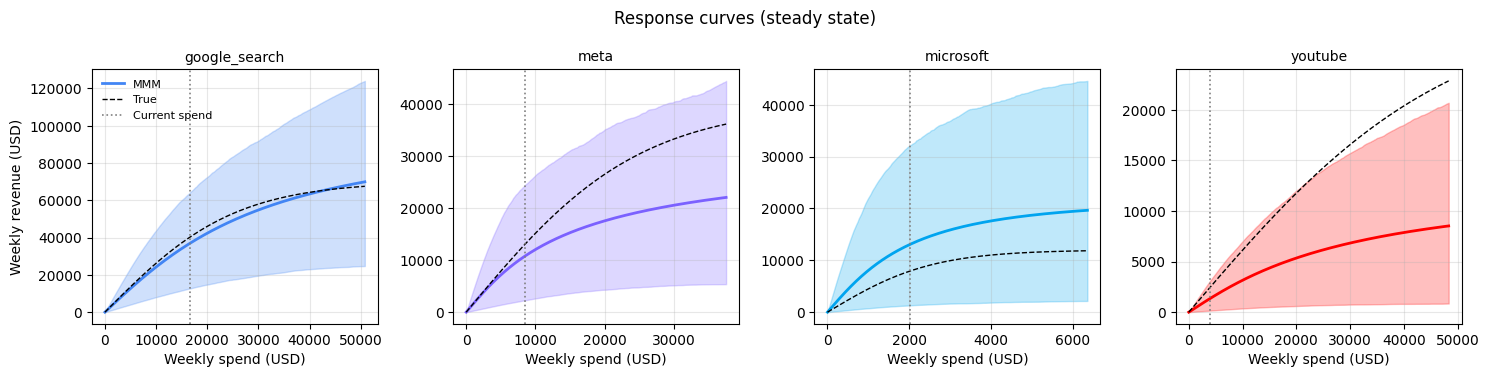


Average vs marginal ROAS at current spend
                weekly_spend  avg_roas  marginal_roas  marginal_5%  marginal_95%  true_marginal_roas
channel                                                                                            
google_search      16619.60      2.22           1.70         0.54          2.93                1.84
meta                8485.79      1.27           0.89         0.23          1.73                1.43
microsoft           2010.91      6.48           3.65         0.33          8.71                2.66
youtube             4023.75      0.34           0.33         0.04          0.74                0.62

Recommended reallocation (same total budget)
                current_weekly  optimal_weekly  change_usd  change_%
google_search         16620.0         21869.0      5249.0      32.0
meta                   8486.0          4243.0     -4243.0     -50.0
microsoft              2011.0          3016.0      1005.0      50.0
youtube                4024.0        

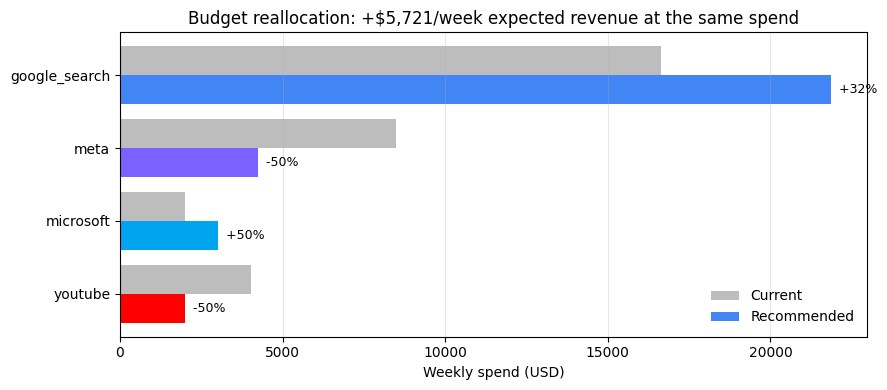

In [3]:
# ============================================================
# Project 3 - Marketing Mix Model
# Step 5: Response curves, marginal ROAS and budget optimisation
# Run in the SAME notebook after Steps 3-4 (uses mmm, df, channels, y_scale, truth, colors)
# ============================================================
from scipy.optimize import minimize
pd.set_option("display.max_columns", 20)

# ------------------------------------------------------------
# 1. Response function from the posterior
#    Steady state (same spend every week): normalised geometric adstock of a
#    constant x equals x, so weekly revenue = beta * logistic(lam * x / channel_scale)
# ------------------------------------------------------------
def draws(var):
    return mmm.idata.posterior[var].stack(sample=("chain", "draw"))

ch_scale = mmm.get_scales_as_xarray()["channel_scale"]

beta = {ch: draws("saturation_beta").sel(channel=ch).values * y_scale for ch in channels}   # USD
lam = {ch: draws("saturation_lam").sel(channel=ch).values for ch in channels}
scale = {ch: float(ch_scale.sel(channel=ch)) for ch in channels}

def logistic(z):
    return (1 - np.exp(-z)) / (1 + np.exp(-z))

def response(ch, weekly_spend):
    """Weekly revenue from a channel at a steady weekly spend. Returns (n_spend, n_draws)."""
    x = np.atleast_1d(weekly_spend)[:, None] / scale[ch]
    return beta[ch][None, :] * logistic(lam[ch][None, :] * x)

def true_response(ch, weekly_spend):
    """Same curve using the TRUE simulation parameters (for validation only)."""
    p = truth[ch]
    return p["beta"] * logistic(p["lam"] * np.asarray(weekly_spend) / scale[ch])

# Current plan = average weekly spend over the last 52 weeks
current = df[channels].iloc[-52:].mean()
weekly_budget = current.sum()
print("Current average weekly spend (last 52 weeks)\n", current.round(0))
print(f"Total weekly budget: ${weekly_budget:,.0f}")

# ------------------------------------------------------------
# 2. Response curves
# ------------------------------------------------------------
fig, axes = plt.subplots(1, len(channels), figsize=(15, 3.8))
for ax, ch in zip(axes, channels):
    grid = np.linspace(0, 2 * df[ch].max(), 200)
    r = response(ch, grid)
    ax.fill_between(grid, *np.percentile(r, [5, 95], axis=1), color=colors[ch], alpha=0.25)
    ax.plot(grid, r.mean(axis=1), color=colors[ch], lw=2, label="MMM")
    ax.plot(grid, true_response(ch, grid), color="black", ls="--", lw=1, label="True")
    ax.axvline(current[ch], color="grey", ls=":", lw=1.2, label="Current spend")
    ax.set_title(ch, fontsize=10)
    ax.set_xlabel("Weekly spend (USD)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Weekly revenue (USD)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Response curves (steady state)")
plt.tight_layout()
plt.savefig("figures/11_response_curves.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 3. Average vs marginal ROAS at current spend
#    Average ROAS  = revenue / spend          (how good was it overall?)
#    Marginal ROAS = revenue from the NEXT $1 (where should the next dollar go?)
# ------------------------------------------------------------
rows = []
for ch in channels:
    x = current[ch]
    avg = response(ch, x)[0] / x
    marg = (response(ch, x * 1.01)[0] - response(ch, x)[0]) / (x * 0.01)
    true_marg = (true_response(ch, x * 1.01) - true_response(ch, x)) / (x * 0.01)
    rows.append({
        "channel": ch,
        "weekly_spend": x,
        "avg_roas": avg.mean(),
        "marginal_roas": marg.mean(),
        "marginal_5%": np.percentile(marg, 5),
        "marginal_95%": np.percentile(marg, 95),
        "true_marginal_roas": true_marg,
    })
mroas = pd.DataFrame(rows).set_index("channel")
print("\nAverage vs marginal ROAS at current spend\n", mroas.round(2))

# ------------------------------------------------------------
# 4. Budget optimiser: same total budget, re-split across channels
#    Guardrails: each channel can move between 50% and 150% of current spend
# ------------------------------------------------------------
def expected_revenue(alloc):
    return sum(response(ch, a)[0].mean() for ch, a in zip(channels, alloc))

# Optimise over budget SHARES (0-1) so the solver works on a well-scaled problem
s0 = (current / weekly_budget).values
bounds = [(0.5 * s, 1.5 * s) for s in s0]
res = minimize(
    lambda s: -expected_revenue(s * weekly_budget) / 1e3,
    s0,
    method="SLSQP",
    bounds=bounds,
    constraints=[{"type": "eq", "fun": lambda s: s.sum() - 1}],
)
optimal = pd.Series(res.x * weekly_budget, index=channels)

# Uplift with uncertainty: evaluate both plans on every posterior draw
cur_draws = sum(response(ch, current[ch])[0] for ch in channels)
opt_draws = sum(response(ch, optimal[ch])[0] for ch in channels)
uplift = opt_draws - cur_draws

# Validate against the TRUE response curves
true_cur = sum(true_response(ch, current[ch]) for ch in channels)
true_opt = sum(true_response(ch, optimal[ch]) for ch in channels)

plan = pd.DataFrame({
    "current_weekly": current.round(0),
    "optimal_weekly": optimal.round(0),
    "change_usd": (optimal - current).round(0),
    "change_%": ((optimal / current - 1) * 100).round(0),
})
print("\nRecommended reallocation (same total budget)\n", plan)
print(f"\nExpected media revenue per week: ${cur_draws.mean():,.0f} -> ${opt_draws.mean():,.0f}")
print(f"Uplift per week: ${uplift.mean():,.0f}  (90% interval ${np.percentile(uplift, 5):,.0f} to ${np.percentile(uplift, 95):,.0f})")
print(f"Probability the new plan beats the current one: {(uplift > 0).mean():.0%}")
print(f"Annualised uplift: ${uplift.mean() * 52:,.0f}")
print(f"\nTRUE uplift per week (ground truth check): ${true_opt - true_cur:,.0f}")

# ------------------------------------------------------------
# 5. Chart: current vs recommended split
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
ypos = np.arange(len(channels))
ax.barh(ypos - 0.2, current, height=0.4, color="#BDBDBD", label="Current")
ax.barh(ypos + 0.2, optimal, height=0.4, color=[colors[c] for c in channels], label="Recommended")
for i, ch in enumerate(channels):
    ax.text(optimal[ch], i + 0.2, f"  {plan.loc[ch, 'change_%']:+.0f}%", va="center", fontsize=9)
ax.set_yticks(ypos, channels)
ax.invert_yaxis()
ax.set_xlabel("Weekly spend (USD)")
ax.set_title(f"Budget reallocation: +${uplift.mean():,.0f}/week expected revenue at the same spend")
ax.legend(frameon=False)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig("figures/12_budget_reallocation.png", dpi=150)
plt.show()